# MANTA: SMALL-E side-by-side stereo calibration

This notebook is the SMALL-E counterpart to the WALL-E calibration tutorial. SMALL-E records both synchronized camera views in one side-by-side video frame. The workflow splits each frame in memory, calibrates the two views, exports a portable calibration, and validates it on checkerboard frames excluded from fitting. It defaults to the 2024 Bocas recording.


## 1. Configuration

Edit this cell to reuse the workflow with another SMALL-E recording. `LAYOUT = 'left_right'` means the physical left camera is stored in the left half of each video frame. `CHECKERBOARD_SIZE` is the number of internal corners, not squares. The Bocas metadata records an 8 × 6 internal-corner board with 21 mm squares.


In [3]:
import os
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np

from stereo_calibration import (
    calibrate_stereo, detect_checkerboard_pairs_side_by_side,
    load_detection_cache, read_side_by_side_pair, rectify_pair,
    save_calibration, save_detection_cache, select_calibration_pairs,
    vertical_disparity,
)

WALL_E_ROOT = Path(os.environ.get(
    'WALL_E_ROOT',
    '/Users/oakley/Documents/GitHub/WALL-E/nextflow',
))
STEREO_VIDEO = WALL_E_ROOT / 'video_data/2024bocas.mp4'
LAYOUT = 'left_right'
CHECKERBOARD_SIZE = (8, 6)  # internal corners: columns, rows
SQUARE_SIZE = 21.0          # mm; recorded in the Bocas 2024 metadata
START_FRAME = 0
END_FRAME = None            # use an integer to limit the scan
FRAME_STEP = 5              # sample at 6 Hz; use 1 only for an exhaustive scan
DETECTION_SCALE = 0.5       # locate at half resolution, then refine at full resolution

N_CALIBRATION_PAIRS = 40
MIN_BOARD_SCALE = 95
MIN_BORDER_CLEARANCE = 100
MAX_MOVEMENT = 10         # combined displacement between consecutive detections
VALIDATION_BLOCK_SIZE_FRAMES = 300  # 10 seconds at 30 fps
VALIDATION_EVERY_NTH_BLOCK = 5

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
CALIBRATION_FILE = PROJECT_ROOT / 'data/processed/2024bocas_smalle_stereo_calibration.npz'

if not STEREO_VIDEO.exists():
    raise FileNotFoundError(f'Missing side-by-side calibration video: {STEREO_VIDEO}')

cap = cv2.VideoCapture(str(STEREO_VIDEO))
FULL_FRAME_SIZE = (
    int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
    int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
)
FRAME_COUNT = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
FPS = cap.get(cv2.CAP_PROP_FPS)
cap.release()
if FULL_FRAME_SIZE[0] % 2:
    raise ValueError(f'Side-by-side frame width must be even: {FULL_FRAME_SIZE[0]}')
IMAGE_SIZE = (FULL_FRAME_SIZE[0] // 2, FULL_FRAME_SIZE[1])

print('Side-by-side video:', STEREO_VIDEO)
print(f'{FRAME_COUNT} frames at {FPS:g} fps; full={FULL_FRAME_SIZE}; each view={IMAGE_SIZE}')
print('Calibration output:', CALIBRATION_FILE)


Side-by-side video: /Users/oakley/Documents/GitHub/WALL-E/nextflow/video_data/2024bocas.mp4
5394 frames at 30 fps; full=(3840, 1080); each view=(1920, 1080)
Calibration output: /Users/oakley/Documents/GitHub/manta-analysis/data/processed/2024bocas_smalle_stereo_calibration.npz


## 2. Detect paired checkerboards

Each 3840 × 1080 frame is split into two synchronized 1920 × 1080 views in memory; no intermediate left and right videos are created. Detection is the slowest step, so results and refined corners are cached. Leave `READ_DETECTIONS_FROM_CACHE = True` to reuse a compatible cache, or set it to `False` to force a new scan.


In [4]:
READ_DETECTIONS_FROM_CACHE = True
DETECTION_CACHE_FILE = PROJECT_ROOT / 'data/processed/2024bocas_smalle_checkerboard_detections.npz'

detection_settings = {
    'stereo_video': str(STEREO_VIDEO.resolve()),
    'layout': LAYOUT,
    'checkerboard_size': list(CHECKERBOARD_SIZE),
    'start_frame': START_FRAME,
    'end_frame': END_FRAME,
    'frame_step': FRAME_STEP,
    'movement_units': 'displacement_and_pixels_per_frame',
    'cache_version': 3,
    'detection_scale': DETECTION_SCALE,
}

if READ_DETECTIONS_FROM_CACHE and DETECTION_CACHE_FILE.exists():
    detections, corner_pairs, cached_settings = load_detection_cache(DETECTION_CACHE_FILE)
    if cached_settings != detection_settings:
        raise ValueError(
            'Detection cache settings do not match this notebook configuration. '
            'Set READ_DETECTIONS_FROM_CACHE = False to detect again and replace the cache.\n'
            f'Cached: {cached_settings}\nCurrent: {detection_settings}'
        )
    print('Loaded detections from:', DETECTION_CACHE_FILE)
else:
    print('Detecting checkerboards in the side-by-side video.')
    detections, corner_pairs = detect_checkerboard_pairs_side_by_side(
        STEREO_VIDEO, CHECKERBOARD_SIZE, layout=LAYOUT,
        start_frame=START_FRAME, end_frame=END_FRAME, frame_step=FRAME_STEP,
        detection_scale=DETECTION_SCALE,
    )
    save_detection_cache(
        DETECTION_CACHE_FILE, detections, corner_pairs, metadata=detection_settings
    )
    print('Saved detections to:', DETECTION_CACHE_FILE)

print(f'Found {len(detections)} paired checkerboard frames')
detections.head()


Loaded detections from: /Users/oakley/Documents/GitHub/manta-analysis/data/processed/2024bocas_smalle_checkerboard_detections.npz
Found 592 paired checkerboard frames


,frame_left,frame_right,board_scale,border_clearance,movement,center_x,center_y
0,20,20,99.555740,244.708740,NaN,953.560272,545.989960
1,25,25,99.238686,250.694275,8.675455,950.876312,540.490601
2,30,30,99.345657,240.417328,14.715608,943.153809,533.529114
3,35,35,98.758141,235.014542,14.404203,933.281097,531.066956
4,40,40,98.337982,228.825821,10.931232,926.106750,528.208679


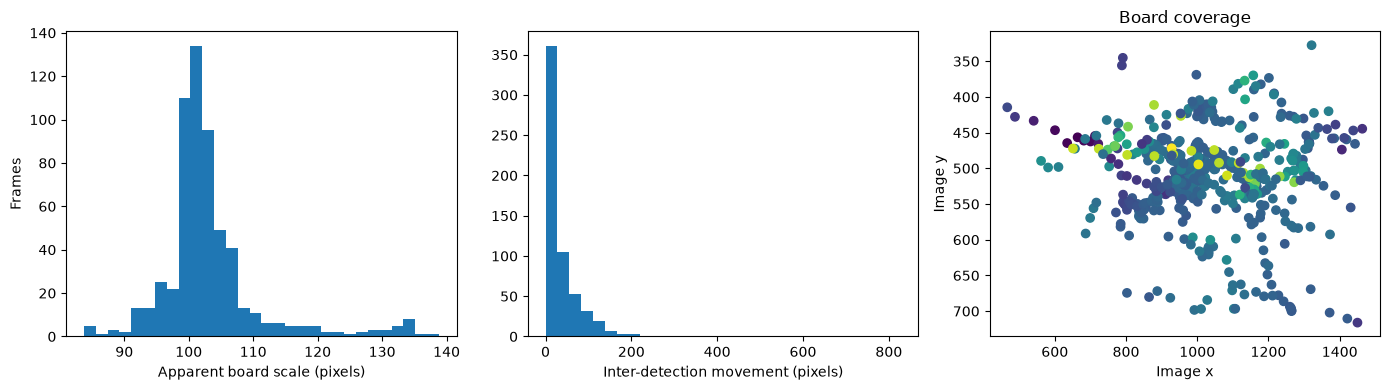

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].hist(detections.board_scale, bins=30)
axes[0].set(xlabel='Apparent board scale (pixels)', ylabel='Frames')
axes[1].hist(detections.movement.dropna(), bins=30)
axes[1].axvline(MAX_MOVEMENT, color='crimson', linestyle='--', label='selection threshold')
axes[1].set(xlabel='Displacement between detections (pixels)')
axes[1].legend()
axes[2].hist(detections.movement_per_frame.dropna(), bins=30)
axes[2].set(xlabel='Movement rate (combined pixels/frame)')
axes[3].scatter(detections.center_x, detections.center_y, c=detections.board_scale)
axes[3].invert_yaxis()
axes[3].set(xlabel='Mean image x', ylabel='Mean image y', title='Mean board coverage')
plt.tight_layout()


## 3. Split validation blocks, then select calibration frames

Complete time blocks are reserved before selection so neighboring frames cannot leak into calibration and validation. The remaining pool is filtered for clear, stable boards and sampled for diverse positions and apparent distances. Tune the thresholds from the plots above rather than assuming the WALL-E values transfer to the higher-resolution SMALL-E video.


Selected 40 calibration pairs; reserved 82 quality-matched validation pairs


Text(0.5, 1.0, 'Selected image coverage')

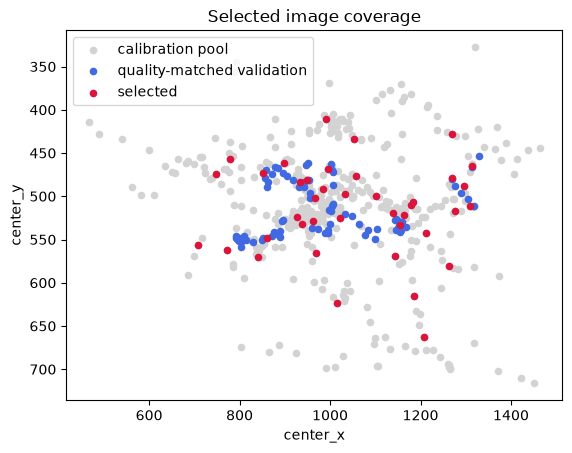

In [6]:
if detections.empty:
    raise RuntimeError('No paired checkerboards were detected; check paths, synchronization, and board size.')
if VALIDATION_EVERY_NTH_BLOCK < 2:
    raise ValueError('VALIDATION_EVERY_NTH_BLOCK must be at least 2.')

ordered = detections.sort_values('frame_left').reset_index(drop=True).copy()
ordered['temporal_block'] = ordered.frame_left // VALIDATION_BLOCK_SIZE_FRAMES
validation_mask = ordered.temporal_block.mod(VALIDATION_EVERY_NTH_BLOCK).eq(
    VALIDATION_EVERY_NTH_BLOCK - 1
)
calibration_pool = ordered.loc[~validation_mask].copy()
held_out = ordered.loc[validation_mask].copy()
if held_out.empty:
    raise RuntimeError('No validation block was created; reduce VALIDATION_BLOCK_SIZE_FRAMES.')
validation = held_out[
    (held_out.board_scale >= MIN_BOARD_SCALE)
    & (held_out.border_clearance >= MIN_BORDER_CLEARANCE)
    & (held_out.movement.fillna(np.inf) <= MAX_MOVEMENT)
].copy()
if validation.empty:
    raise RuntimeError('No held-out detections passed the calibration-quality thresholds.')

selected = select_calibration_pairs(
    calibration_pool, number=N_CALIBRATION_PAIRS, min_board_scale=MIN_BOARD_SCALE,
    min_border_clearance=MIN_BORDER_CLEARANCE, max_movement=MAX_MOVEMENT,
)
print(
    f'Selected {len(selected)} calibration pairs; '
    f'reserved {len(validation)} quality-matched validation pairs'
)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for ax, side in zip(axes, ['left', 'right']):
    xcol, ycol = f'center_{side}_x', f'center_{side}_y'
    calibration_pool.plot.scatter(
        x=xcol, y=ycol, color='lightgray', label='calibration pool', ax=ax
    )
    validation.plot.scatter(
        x=xcol, y=ycol, color='royalblue', label='quality-matched validation', ax=ax
    )
    selected.plot.scatter(
        x=xcol, y=ycol, color='crimson', label='selected', ax=ax
    )
    ax.invert_yaxis()
    ax.set(title=f'{side.title()} camera coverage', xlabel='Image x', ylabel='Image y')
plt.tight_layout()


## 4. Calibrate

The translation vector and subsequent reconstructed coordinates use the same unit as `SQUARE_SIZE`.

In [7]:
calibration = calibrate_stereo(
    selected, corner_pairs, CHECKERBOARD_SIZE, SQUARE_SIZE, IMAGE_SIZE
)
print('Left RMS reprojection error:', calibration['rms_left'])
print('Right RMS reprojection error:', calibration['rms_right'])
print('Stereo RMS error:', calibration['rms_stereo'])
print('Estimated baseline:', np.linalg.norm(calibration['translation']), 'mm')
save_calibration(CALIBRATION_FILE, calibration)
print('Saved:', CALIBRATION_FILE)

with np.load(CALIBRATION_FILE) as archive:
    calibration = {name: archive[name] for name in archive.files}
print(f'Reloaded {len(calibration)} calibration fields from disk')


Left RMS reprojection error: 1.3300340031136417
Right RMS reprojection error: 1.7572093209872048
Stereo RMS error: 1.622586335743729
Estimated baseline: 59.13152920875143 mm
Saved: /Users/oakley/Documents/GitHub/manta-analysis/data/processed/2024bocas_smalle_stereo_calibration.npz
Reloaded 21 calibration fields from disk


## 5. Validate on quality-matched reserved checkerboards

This is a small guard against accepting a calibration that fits its selected frames but fails elsewhere in the recording. The test uses only reserved frames that pass the **same board-scale, border-clearance, and movement thresholds** as the calibration candidates. Moving, distant, and otherwise out-of-scope detections are retained in `held_out` for optional diagnostics, but they do not determine whether the calibration passes.

In [10]:
held_out['median_vertical_error'] = [
    np.median(vertical_disparity(*corner_pairs[int(frame)], calibration))
    for frame in held_out.frame_left
]
held_out['max_vertical_error'] = [
    np.max(vertical_disparity(*corner_pairs[int(frame)], calibration))
    for frame in held_out.frame_left
]
validation = held_out.loc[validation.index].copy()
validation_errors = np.concatenate([
    vertical_disparity(*corner_pairs[int(frame)], calibration)
    for frame in validation.frame_left
])
print(f'Quality-matched validation frames: {len(validation)}')
print(f'Checkerboard corners: {len(validation_errors)}')
print(f'Median vertical disparity: {np.median(validation_errors):.3f} px')
print(f'95th percentile: {np.percentile(validation_errors, 95):.3f} px')
print(f'Maximum: {np.max(validation_errors):.3f} px')
validation[['median_vertical_error', 'max_vertical_error']].describe()

Quality-matched validation frames: 82
Checkerboard corners: 3936
Median vertical disparity: 0.598 px
95th percentile: 2.424 px
Maximum: 23.125 px


,median_vertical_error,max_vertical_error
count,82.000000,82.000000
mean,0.665312,4.595036
std,0.356995,4.078321
min,0.297791,1.339172
25%,0.459106,2.221008
50%,0.549253,3.336517
75%,0.740803,4.951736
max,2.618010,23.125366


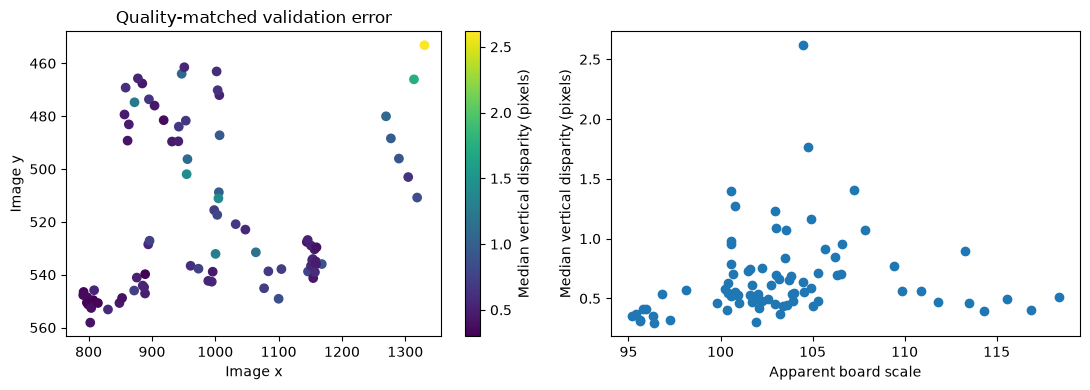

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sc = axes[0].scatter(validation.center_x, validation.center_y, c=validation.median_vertical_error)
axes[0].invert_yaxis(); axes[0].set(title='Quality-matched validation error', xlabel='Image x', ylabel='Image y')
fig.colorbar(sc, ax=axes[0], label='Median vertical disparity (pixels)')
axes[1].scatter(validation.board_scale, validation.median_vertical_error)
axes[1].set(xlabel='Apparent board scale', ylabel='Median vertical disparity (pixels)')
plt.tight_layout()

## 6. Visual epipolar-line check

Inspect the quality-matched validation frame with the largest median vertical error. The cell reads one side-by-side source frame, separates its two views, rectifies them, and draws shared horizontal guides. Corresponding checkerboard corners and scene features should lie on the same guides.


Text(0.5, 1.0, 'Worst held-out frame 1470: median vertical error 1.26 px')

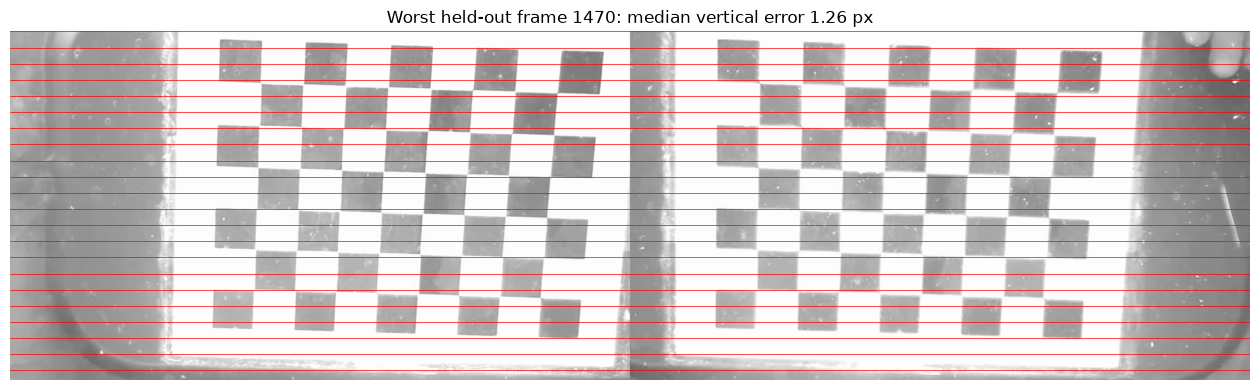

In [24]:
example = validation.loc[validation.median_vertical_error.idxmax()]
frame = int(example.frame_left)
image_l, image_r = read_side_by_side_pair(STEREO_VIDEO, frame, layout=LAYOUT)
rect_l, rect_r = rectify_pair(image_l, image_r, calibration)
combined = np.hstack([
    cv2.cvtColor(rect_l, cv2.COLOR_BGR2RGB),
    cv2.cvtColor(rect_r, cv2.COLOR_BGR2RGB),
])
plt.figure(figsize=(16, 6)); plt.imshow(combined)
for y in range(0, combined.shape[0], 50):
    plt.axhline(y, color='red', linewidth=0.5)
plt.axis('off')
plt.title(
    f'Worst held-out frame {frame}: median vertical error '
    f'{example.median_vertical_error:.2f} px'
)
